<a href="https://colab.research.google.com/github/sergioingmeca-cyber/portafolio/blob/main/E_Commerce_Database_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-Commerce Database Project - Analisis de desempeño por medio de SQL

***Problema de negocio***

Una empresa de e-commerce quiere entender qué factores están impulsando sus ingresos, qué clientes generan mayor valor y dónde existen oportunidades para mejorar ventas e inventario.

***Analisis exploratorio***

In [4]:
import pandas as pd
import sqlite3

In [5]:
ruta_db = "store.db"
#Conector a base de Datos
conn = sqlite3.connect(ruta_db)
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

              name
0       categories
1        customers
2      order_items
3           orders
4         products
5  sqlite_sequence


In [6]:
#Exploracion de tablas
query = "SELECT * FROM categories;"
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

   category_id           category_name
0            1             Electronics
1            2          Home & Kitchen
2            3                Clothing
3            4                   Books
4            5       Sports & Outdoors
5            6  Beauty & Personal Care
6            7            Toys & Games


In [7]:
#Exploracion de tablas
query = "SELECT * FROM Customers "
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

     customer_id first_name last_name                              email  \
0              1   Danielle   Johnson      danielle.johnson655@yahoo.com   
1              2   Patricia    Miller       patricia.miller115@yahoo.com   
2              3       Anna   Baldwin         anna.baldwin26@hotmail.com   
3              4       Adam   Shaffer        adam.shaffer760@hotmail.com   
4              5    Matthew     Davis         matthew.davis282@gmail.com   
..           ...        ...       ...                                ...   
195          196  Nathaniel    Hughes       nathaniel.hughes12@gmail.com   
196          197      Debra     Moody           debra.moody697@gmail.com   
197          198  Katherine  Harrison  katherine.harrison739@hotmail.com   
198          199     Shelby     Lynch          shelby.lynch118@yahoo.com   
199          200     Robert     Bauer          robert.bauer699@yahoo.com   

                    city state country signup_date  
0            East Donald    CT    

In [8]:
#Exploracion de tablas
query = "SELECT * FROM order_items"
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

      order_item_id  order_id  product_id  quantity  unit_price
0                 1         5          48         2      144.53
1                 2         5          57         3       61.52
2                 3         5          10         4       93.04
3                 4       522          36         1       23.89
4                 5       522          32         2       96.96
...             ...       ...         ...       ...         ...
2451           2452       343           9         2       36.39
2452           2453       343          11         4      154.76
2453           2454       343          44         1      148.20
2454           2455       343          41         4      272.10
2455           2456       343          52         1      259.83

[2456 rows x 5 columns]


In [9]:
#Exploracion de tablas
query = "SELECT * FROM orders"
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

     order_id  customer_id  order_date     status
0           1           63  2025-10-22  cancelled
1           2           92  2025-09-11  delivered
2           3          126  2025-12-25    shipped
3           4            6  2025-02-15  cancelled
4           5            2  2024-07-19  delivered
..        ...          ...         ...        ...
795       796           95  2025-06-12    shipped
796       797           23  2024-12-31  delivered
797       798           81  2025-08-26  delivered
798       799          155  2025-04-18  delivered
799       800          160  2024-11-30  delivered

[800 rows x 4 columns]


In [10]:
#Exploracion de tablas
query = "SELECT * FROM products "
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

    product_id       product_name  category_id  unit_price  stock_quantity
0            1         Headphones            1      266.01             384
1            2  Bluetooth Speaker            1       83.71             328
2            3             Webcam            1      105.35             150
3            4         Smartwatch            1      133.26             232
4            5            Charger            1        5.96             369
..         ...                ...          ...         ...             ...
65          66               Doll            7      278.28             434
66          67          Card Game            7       74.73             208
67          68          Plush Toy            7      148.26             109
68          69              Drone            7      260.07             462
69          70            Art Set            7       22.30             194

[70 rows x 5 columns]


In [11]:
#Datos en cada tabla
query = "SELECT * FROM sqlite_sequence "
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

          name   seq
0   categories     7
1    customers   200
2     products    70
3       orders   800
4  order_items  2456


Preguntas de negocio
+ ¿Cómo evolucionan los ingresos mensualmente?
+ ¿Cuáles son las categorías más rentables?
+ ¿Qué productos generan más ingresos?
+ ¿Quiénes son los clientes de mayor valor?
+ ¿Cuál es la tasa de recompra?
+ ¿Qué productos tienen bajo inventario?
+ ¿Qué meses presentan mayor facturación?
+ ¿Qué porcentaje de ingresos proviene de los principales clientes?

In [12]:
# Identificamos que en la tabla order_item encontramos cantidades vendidad y precio unitario, pero no un precio total
# de venta que calcularemos en la siguiente query
query = """
SELECT order_item_id, order_id, product_id, quantity, unit_price
FROM order_items
WHERE product_id = '1'
LIMIT 10
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

   order_item_id  order_id  product_id  quantity  unit_price
0            160       707           1         2      266.01
1            188       697           1         4      266.01
2            204       184           1         4      266.01
3            270       388           1         2      266.01
4            277       500           1         3      266.01
5            341       689           1         3      266.01
6            541        99           1         3      266.01
7            562       253           1         1      266.01
8            696       447           1         2      266.01
9            813       374           1         4      266.01


In [13]:
#Calculo de ingreso total
query = """
SELECT order_item_id,
       order_id,
       product_id,
       quantity,
       unit_price,
       (COALESCE(quantity,0) * COALESCE(unit_price,0)) AS total_price
FROM order_items
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

      order_item_id  order_id  product_id  quantity  unit_price  total_price
0                 1         5          48         2      144.53       289.06
1                 2         5          57         3       61.52       184.56
2                 3         5          10         4       93.04       372.16
3                 4       522          36         1       23.89        23.89
4                 5       522          32         2       96.96       193.92
...             ...       ...         ...       ...         ...          ...
2451           2452       343           9         2       36.39        72.78
2452           2453       343          11         4      154.76       619.04
2453           2454       343          44         1      148.20       148.20
2454           2455       343          41         4      272.10      1088.40
2455           2456       343          52         1      259.83       259.83

[2456 rows x 6 columns]


In [14]:
#Se extrae el mes y el año para identificar las ventas en el tiempo
query = """
SELECT oi.order_item_id,
       oi.order_id,
       oi.product_id,
       oi.quantity,
       oi.unit_price,
       (COALESCE(oi.quantity,0) * COALESCE(oi.unit_price,0)) AS total_price,
       STRFTIME('%Y-%m', o.order_date) AS fecha
FROM order_items AS oi
JOIN orders AS o
  ON oi.order_id = o.order_id
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

      order_item_id  order_id  product_id  quantity  unit_price  total_price  \
0                 1         5          48         2      144.53       289.06   
1                 2         5          57         3       61.52       184.56   
2                 3         5          10         4       93.04       372.16   
3                 4       522          36         1       23.89        23.89   
4                 5       522          32         2       96.96       193.92   
...             ...       ...         ...       ...         ...          ...   
2451           2452       343           9         2       36.39        72.78   
2452           2453       343          11         4      154.76       619.04   
2453           2454       343          44         1      148.20       148.20   
2454           2455       343          41         4      272.10      1088.40   
2455           2456       343          52         1      259.83       259.83   

        fecha  
0     2024-07  
1     2

In [15]:
#Ventas en el periodo 2024 - 07 a 2026 - 07
query = """
SELECT
     STRFTIME('%Y-%m', o.order_date) AS fecha,
     SUM(COALESCE(oi.quantity,0) * COALESCE(oi.unit_price,0)) AS total_price
FROM order_items AS oi
JOIN orders AS o
  ON oi.order_id = o.order_id
GROUP BY fecha
ORDER BY fecha
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

      fecha  total_price
0   2024-07     10835.49
1   2024-08     43464.88
2   2024-09     33520.31
3   2024-10     38482.32
4   2024-11     24864.46
5   2024-12     29775.16
6   2025-01     30648.77
7   2025-02     39019.85
8   2025-03     32908.80
9   2025-04     45760.20
10  2025-05     49381.41
11  2025-06     64571.88
12  2025-07     31335.74
13  2025-08     36252.65
14  2025-09     34062.43
15  2025-10     34932.23
16  2025-11     37142.24
17  2025-12     45304.64
18  2026-01     29495.58
19  2026-02     25614.68
20  2026-03     30000.96
21  2026-04     30842.65
22  2026-05     44251.46
23  2026-06     29881.04
24  2026-07     23448.88


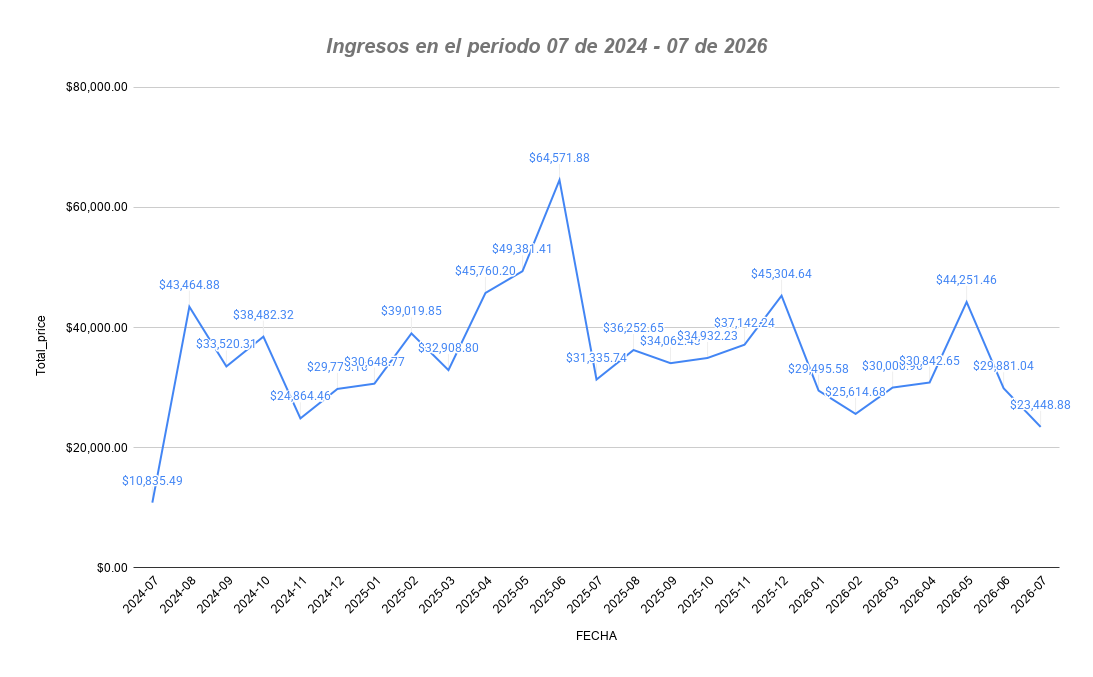

In [16]:
#Ventas por Categoria
query = """
SELECT
     p.category_id,
     c.category_name,
     SUM(COALESCE(oi.quantity,0) * COALESCE(oi.unit_price,0)) AS total_price
FROM order_items AS oi
JOIN products AS p
  ON oi.product_id = p.product_id
JOIN categories AS c
    ON p.category_id = c.category_id
GROUP BY p.category_id
ORDER BY total_price DESC;
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

   category_id           category_name  total_price
0            2          Home & Kitchen    137363.66
1            5       Sports & Outdoors    135881.01
2            7            Toys & Games    132302.32
3            3                Clothing    126662.31
4            6  Beauty & Personal Care    118815.98
5            1             Electronics    117818.16
6            4                   Books    106955.27


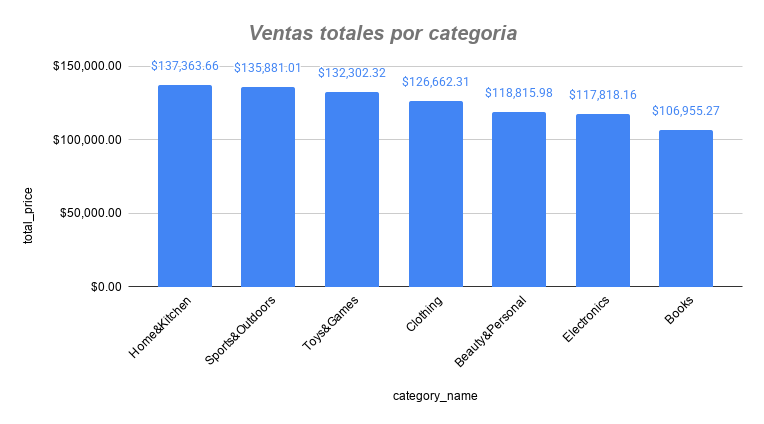

In [17]:
#Ranking de productos por categoria
query = """
WITH ranking_de_ventas AS (
SELECT
      c.category_name,
      p.product_name,
      SUM(COALESCE(oi.quantity,0) * COALESCE(oi.unit_price,0)) AS total_price,
      RANK() OVER (PARTITION BY c.category_name ORDER BY SUM(COALESCE(oi.quantity,0) * COALESCE(oi.unit_price,0)) DESC) AS ranking
FROM order_items AS oi
JOIN products AS p
  ON oi.product_id = p.product_id
JOIN categories AS c
  ON p.category_id = c.category_id
GROUP BY c.category_name, p.product_name
)
SELECT *
FROM ranking_de_ventas
WHERE ranking <= 3
ORDER BY category_name, ranking;
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

             category_name      product_name  total_price  ranking
0   Beauty & Personal Care          Lipstick     23586.29        1
1   Beauty & Personal Care        Face Cream     21565.89        2
2   Beauty & Personal Care           Perfume     15883.92        3
3                    Books   Self-Help Guide     23253.54        1
4                    Books           Journal     18569.20        2
5                    Books         Biography     17507.19        3
6                 Clothing             Scarf     22869.71        1
7                 Clothing               Hat     18628.27        2
8                 Clothing            Jacket     18184.02        3
9              Electronics           Monitor     28971.80        1
10             Electronics          Keyboard     27712.45        2
11             Electronics        Headphones     21014.79        3
12          Home & Kitchen              Lamp     26686.22        1
13          Home & Kitchen            Vacuum     25581.21     

In [18]:
#TOP 10 Producto con mas Ventas
query = """
SELECT
     p.product_name,
     SUM(COALESCE(oi.quantity,0) * COALESCE(oi.unit_price,0)) AS total_price
FROM order_items AS oi
JOIN products AS p
  ON oi.product_id = p.product_id
GROUP BY p.product_name
ORDER BY total_price DESC
Limit 10
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

      product_name  total_price
0         Yoga Mat     35373.00
1  Building Blocks     29079.63
2          Monitor     28971.80
3         Keyboard     27712.45
4             Lamp     26686.22
5           Vacuum     25581.21
6             Doll     25045.20
7            Drone     24446.58
8         Lipstick     23586.29
9      Storage Bin     23328.00


In [19]:
#TOP 10 Producto con menos Ventas
query = """
SELECT
     p.product_name,
     SUM(COALESCE(oi.quantity,0) * COALESCE(oi.unit_price,0)) AS total_price
FROM order_items AS oi
JOIN products AS p
  ON oi.product_id = p.product_id
GROUP BY p.product_name
ORDER BY total_price ASC
Limit 10
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

   product_name  total_price
0       Charger       506.60
1        RC Car       776.05
2     Guidebook      1051.39
3         Comic      1624.52
4       Art Set      1828.60
5     Knife Set      2164.82
6        Tablet      2547.30
7    Board Game      2724.00
8  History Book      2775.58
9      Textbook      2849.00


In [20]:
#Producto con mas unidades vendidas
query = """
SELECT
     p.product_name,
     SUM(COALESCE(oi.quantity,0)) AS unidades_vendidas
FROM order_items AS oi
JOIN products AS p
  ON oi.product_id = p.product_id
GROUP BY p.product_name
ORDER BY unidades_vendidas DESC;
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

     product_name  unidades_vendidas
0        Yoga Mat                130
1     Body Lotion                122
2       Card Game                114
3    Water Bottle                110
4         Monitor                110
..            ...                ...
65  Running Shoes                 66
66     Hair Dryer                 60
67         Webcam                 50
68           Tent                 49
69      Guidebook                 47

[70 rows x 2 columns]


In [21]:
#Inventario por producto
query = """
SELECT
   product_id,
   product_name,
   stock_quantity
FROM products
ORDER BY stock_quantity DESC;
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

    product_id       product_name  stock_quantity
0           23             Jacket             500
1           13       Cookware Set             488
2           45        Bike Helmet             478
3           29              Scarf             475
4           60           Nail Kit             472
..         ...                ...             ...
65          40          Guidebook              34
66          52         Face Cream              27
67          36              Comic              10
68          16       Coffee Maker               9
69          38  Poetry Collection               3

[70 rows x 3 columns]


In [22]:
#Listado de Mejores Clientes y Porcentaje de participacion en las ventas
query = """
WITH ventas_cliente AS (
    SELECT
        o.customer_id,
        cl.first_name,
        cl.last_name,
        SUM(COALESCE(oi.quantity, 0) * COALESCE(oi.unit_price, 0)) AS total_price
    FROM order_items AS oi
    JOIN orders AS o
        ON oi.order_id = o.order_id
    JOIN customers AS cl
        ON o.customer_id = cl.customer_id
    GROUP BY
        o.customer_id,
        cl.first_name,
        cl.last_name
)
SELECT
    customer_id,
    first_name,
    last_name,
    total_price,
    ROUND( total_price * 100.0 / SUM(total_price) OVER (), 2)
    AS porcentaje_de_participacion
FROM ventas_cliente
ORDER BY total_price DESC;
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

     customer_id first_name  last_name  total_price  \
0             33       Beth    Daniels     13802.34   
1            126       Mark      Brown     13711.83   
2             95    Barbara      Parks     12076.32   
3            142     Donald       Shah      9985.81   
4             47      Anita     Baxter      9784.54   
..           ...        ...        ...          ...   
192          131     Ashley    Andrews       516.86   
193           51   Michelle  Rasmussen       505.34   
194           41    Darrell  Rodriguez       470.19   
195          198  Katherine   Harrison       250.19   
196          125   Kathleen    Padilla        66.90   

     porcentaje_de_participacion  
0                           1.58  
1                           1.57  
2                           1.38  
3                           1.14  
4                           1.12  
..                           ...  
192                         0.06  
193                         0.06  
194                     

In [23]:
#Estados con mas Ventas
query = """
SELECT
     DISTINCT cl.state,
     COUNT(DISTINCT o.order_id) AS total_orders,
     SUM(COALESCE(oi.quantity,0) * COALESCE(oi.unit_price,0)) AS total_price
FROM order_items AS oi
JOIN orders AS o
  ON oi.order_id = o.order_id
JOIN customers AS cl
    ON o.customer_id = cl.customer_id
GROUP BY cl.state
ORDER BY total_price DESC
LIMIT 10;
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

  state  total_orders  total_price
0    NC            26     36691.26
1    AR            27     34873.41
2    RI            34     34586.46
3    CT            30     32619.57
4    AS            29     32585.52
5    ME            25     31287.80
6    OK            26     29713.12
7    WY            24     24887.57
8    FM            21     24830.11
9    LA            21     21719.74


In [24]:
#Porcentaje de recompra de clientes
query = """
WITH compras_cliente AS (
    SELECT
        customer_id,
        COUNT(DISTINCT order_id) AS total_compras
    FROM orders
    GROUP BY customer_id
)
SELECT
    COUNT(*) AS clientes_compradores,
    SUM(CASE WHEN total_compras >= 2 THEN 1 ELSE 0 END)
    AS clientes_recurrentes,
    ROUND(100.0 * SUM(CASE WHEN total_compras >= 2 THEN 1 ELSE 0 END) / COUNT(*),2)
    AS tasa_recompra
FROM compras_cliente;
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

   clientes_compradores  clientes_recurrentes  tasa_recompra
0                   197                   184           93.4


In [25]:
#INFORME GENERAL DE RESULTADOS
query = """
SELECT
    COUNT(DISTINCT o.order_id) AS total_orders,
    SUM(COALESCE(oi.quantity, 0) * COALESCE(oi.unit_price, 0)) AS total_ventas,
    COUNT(DISTINCT cl.customer_id) AS total_customers,
    COUNT(DISTINCT p.product_id) AS total_products,
    SUM(COALESCE(p.stock_quantity, 0)) AS total_stock,
    COUNT(DISTINCT c.category_id) AS total_categories

FROM order_items AS oi

JOIN orders AS o
    ON oi.order_id = o.order_id
JOIN customers AS cl
    ON o.customer_id = cl.customer_id
JOIN products AS p
    ON oi.product_id = p.product_id
JOIN categories AS c
    ON p.category_id = c.category_id;
"""
df_datos = pd.read_sql_query(query, conn)
print(df_datos)

   total_orders  total_ventas  total_customers  total_products  total_stock  \
0           800     875798.71              197              70       679305   

   total_categories  
0                 7  


# INFORME DE RESULTADOS

## Análisis de ventas, clientes e inventario

### 1. Evolución mensual de los ingresos

Durante el periodo analizado, los ingresos mensuales presentaron fluctuaciones importantes, con meses de alto desempeño comercial y otros con una disminución considerable en las ventas.

* **Mes con mayores ingresos:** julio de 2025, con un total de **$64.571,88**.

* **Mes con menores ingresos:** julio de 2024, con un total de **$10.835,49**.

* **Promedio mensual reportado:** $35.031,95.

Se observa un incremento de los ingresos después del primer mes de análisis. Sin embargo, el comportamiento posterior no es completamente estable, ya que existen variaciones significativas entre los meses. Esta dinámica evidencia la necesidad de identificar los factores que impulsan los periodos de mayor facturación y aquellos que contribuyen a las caídas en las ventas.

### 2. Categorías con mayores ingresos

El análisis de ingresos por categoría permitió identificar diferencias en el desempeño comercial de los productos.

* **Categoría con mayores ingresos:** Home & Kitchen, con **$137.363,66**.

* **Categoría con menores ingresos:** Books, con **$106.955,27**.

Home & Kitchen lidera la generación de ingresos entre las categorías analizadas, mientras que Books presenta la menor facturación. No obstante, estos resultados reflejan ingresos por ventas y no necesariamente rentabilidad neta, dado que no se dispone aquí de información sobre costos, gastos y márgenes por categoría.

### 3. Productos con mayor y menor generación de ingresos

El análisis a nivel de producto permitió identificar cuáles tienen una mayor contribución a los ingresos y cuáles presentan un desempeño comercial más bajo.

* **Producto con mayores ingresos:** Yoga Mat, con **$35.373,00**.

* **Producto con menores ingresos:** Charger, con **$506,60**.

Yoga Mat destaca como el producto con mayor generación de ingresos, por lo que representa una referencia importante para evaluar la demanda y las oportunidades de crecimiento. En contraste, Charger registra la menor facturación, lo que justifica revisar su volumen de ventas, precio, disponibilidad y comportamiento de la demanda antes de tomar decisiones comerciales.

### 4. Clientes de mayor valor

El análisis del gasto acumulado por cliente permitió identificar a los compradores que más contribuyen a los ingresos de la tienda.

* **Beth Daniels:** $13.802,34 en compras - 1.58% de contribucion en las ventas

* **Mark Brown:** $13.711,83 en compras - 1.57% de contribucion en las ventas


La identificación de estos clientes permite explorar estrategias de fidelización y analizar sus hábitos de compra para comprender qué productos o categorías contribuyen a su valor comercial.

### 5. Tasa de recompra de clientes

La tienda cuenta con **197 clientes**, de los cuales 13 han realizado una única compra. Los 184 clientes restantes han efectuado dos o más compras.

Con base en estos datos, la tasa de recompra es del **93,4 %**, lo que indica que una proporción elevada de los clientes registrados ha regresado a comprar.

Este resultado sugiere una recurrencia de compra favorable. Sin embargo, para comprender mejor la fidelidad de los clientes, sería conveniente complementar el indicador con la frecuencia de compra, el tiempo entre pedidos y el valor promedio de las transacciones.

### 6. Estado del inventario

El análisis de las existencias permitió identificar productos con niveles de inventario considerablemente inferiores a los de otros artículos.

* **Producto con mayor inventario:** Jacket, con 500 unidades disponibles.
* **Productos con menor inventario:**

  * Poetry Collection: 3 unidades.
  * Coffee Maker: 9 unidades.
  * Comic: 10 unidades.

Poetry Collection, Coffee Maker y Comic presentan existencias reducidas y podrían estar expuestos a un mayor riesgo de agotamiento si la demanda supera las unidades disponibles.

Por otra parte, el inventario de Jacket asciende a 500 unidades. Esta diferencia evidencia la necesidad de gestionar las existencias de acuerdo con la demanda de cada producto, evitando tanto los quiebres de stock como la acumulación innecesaria de mercancía.

Es importante aclarar que un inventario bajo no implica automáticamente un problema: debe contrastarse con la velocidad de venta, los tiempos de reposición y la demanda esperada.

---

## 7. Recomendaciones estratégicas

### 7.1. Estabilizar y mejorar los ingresos mensuales

* Analizar los meses de mayores y menores ingresos para identificar patrones de estacionalidad, cambios en la demanda y posibles efectos de promociones.
* Comparar los ingresos mes a mes y año a año para distinguir fluctuaciones normales de caídas que requieran intervención.
* Diseñar campañas comerciales en los periodos históricamente más débiles y evaluar sus resultados mediante indicadores de ventas y conversión.

**Objetivo:** reducir la volatilidad de los ingresos y mejorar la planificación comercial.

### 7.2. Potenciar las categorías de mejor desempeño

* Evaluar la demanda y los márgenes de Home & Kitchen para identificar los productos que generan mayor contribución económica.
* Investigar las razones del menor nivel de ingresos de Books, incluyendo la disponibilidad, los precios, la variedad de productos y las preferencias de los clientes.
* Evitar decisiones basadas únicamente en la facturación: incorporar costos y márgenes para determinar qué categorías generan mayor utilidad.

**Objetivo:** orientar las acciones comerciales hacia las categorías con mejores oportunidades de crecimiento y rentabilidad.

### 7.3. Optimizar el portafolio de productos

* Analizar el comportamiento de Yoga Mat para identificar oportunidades de mantener su disponibilidad y aprovechar su buen desempeño.
* Revisar el precio, la demanda y la evolución de las ventas de Charger antes de decidir si conviene promocionarlo, ajustar su estrategia comercial o evaluar su continuidad.
* Identificar productos que se compran conjuntamente para diseñar paquetes comerciales y oportunidades de venta cruzada.

**Objetivo:** incrementar los ingresos por producto y mejorar la eficiencia del portafolio comercial.

### 7.4. Fortalecer la fidelización de clientes

* Diseñar beneficios para clientes recurrentes y compradores de alto valor.
* Analizar las categorías y los productos preferidos por Beth Daniels y Mark Brown para identificar oportunidades de personalización.
* Segmentar a los clientes según frecuencia de compra, gasto acumulado y tiempo desde la última transacción.
* Verificar el porcentaje de participación de cada cliente sobre los ingresos totales para garantizar la consistencia de los indicadores.

**Objetivo:** conservar a los clientes de mayor valor y aumentar la frecuencia y el valor de sus compras.

### 7.5. Mejorar la gestión del inventario

* Revisar prioritariamente las existencias de Poetry Collection, Coffee Maker y Comic, contrastándolas con sus ventas recientes y tiempos de reposición.
* Definir niveles mínimos de inventario y puntos de reorden para reducir el riesgo de agotamiento.
* Evaluar la rotación de Jacket para determinar si las 500 unidades disponibles corresponden a una demanda esperada o a una acumulación de existencias.
* Implementar un seguimiento periódico de productos con inventario crítico y de aquellos con baja rotación.

**Objetivo:** garantizar la disponibilidad de los productos demandados y reducir los costos asociados al exceso de inventario.

---

## 8. Conclusión general

El análisis de la base de datos permitió identificar oportunidades de mejora en cuatro áreas principales: desempeño de ventas, gestión del portafolio de productos, fidelización de clientes y control de inventarios.

Los resultados destacan a Home & Kitchen como la categoría con mayores ingresos, a Yoga Mat como el producto con mayor facturación y una tasa de recompra reportada del 93,4 %. Al mismo tiempo, las fluctuaciones mensuales de los ingresos, la baja facturación de Charger y las existencias reducidas de algunos productos representan aspectos que merecen seguimiento.

Como siguiente paso, se recomienda complementar este análisis con indicadores de margen de utilidad, rotación de inventario, ticket promedio, frecuencia de compra y evolución de clientes activos. De esta manera, el negocio podrá pasar de una descripción de resultados históricos a una gestión comercial basada en datos, con decisiones más precisas y medibles.
